# Ripple rate vs criticality — power-law state analysis

Low/high-ripple avalanche fitting, relating ripple rate to criticality measured through
avalanche power-law statistics, with:

1. bin at the **population mean IEI** per session (~2 ms), not 50 ms;
2. **common xmin** across every group being compared (chosen once on the pooled
   distribution — never per-group auto-KS, never hand-fixed for one group only);
3. **DCC computed over consistent ranges**: tau on sizes >= xmin_S, alpha on durations
   >= xmin_D, and beta_fit on mean-size-per-duration restricted to the same duration
   range — not a full-range beta against tail-restricted exponents;
4. ripple split within **NREM only** (WAKE ripple rate is too low to grade);
5. groups: median split (low/high) **and** terciles, equal avalanche counts.

**Outputs** go to new files only; existing outputs are not modified.
- writes CSVs only to `data/revision/log/ripple_criticality_*.csv`
- writes figures only to `reports/revision_figs/`
- never touches `data/l_h_ripples/log/*`, `reports/new_planc/*`, or anything in
  `R_Project`. The originals used by FigS2_D_E_F stay byte-identical.

A companion mixture-proof test and a ripple-ablation control for the ripple events as
the second mixture component are run separately with `mixture_proof.py`.

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = r"D:\Documents\GitHub\Sleep_criticaltiy"
REV  = os.path.join(REPO, "notebooks", "exploration", "revision")
sys.path.insert(0, REV)

from fig1_metrics import GUARD_S, MIN_FIRING_RATE, build_state_intervals, subtract_intervals
from run_fig1_metrics import assert_local_path
from avalanche_ripple import detect, ripple_rate_at            # mean-IEI detection
from mixture_proof import fit_powerlaw, ks_two_sample, ccdf_at # numpy MLE fits

# --- output locations: NEW files only ---------------------------------------
OUT_CSV_DIR = os.path.join(REPO, "data", "revision", "log")
OUT_FIG_DIR = os.path.join(REPO, "reports", "revision_figs")
for d in (OUT_CSV_DIR, OUT_FIG_DIR):
    assert_local_path(d); os.makedirs(d, exist_ok=True)

FORBIDDEN = [os.path.join(REPO, "data", "l_h_ripples"),
             os.path.join(REPO, "reports", "new_planc"),
             r"D:\Documents\GitHub\R_Project"]
def safe_path(p):
    ap = os.path.abspath(p)
    for f in FORBIDDEN:
        assert not ap.lower().startswith(f.lower()), f"refusing to write into {f}"
    return assert_local_path(ap)

PCT = 30                 # activity threshold percentile (sweep in the batch cell)
RIPPLE_SMOOTH_S = 10.0   # local ripple-rate window (NREM rate ~0.95 Hz -> ~9.5 events)
SEED = 0

## Pipeline

`run_session()` does, per session: avalanche detection in NREM at the mean-IEI bin →
local ripple rate per avalanche → median-split and tercile groups → **one** xmin for
sizes and **one** for durations from the pooled distribution → per-group τ (sizes),
α (durations), β_fit (mean size per duration, durations ≥ xmin_D), β_pred, DCC —
every group over identical ranges, so the numbers are comparable by construction.

In [2]:
def beta_consistent(S, D, xmin_d):
    """beta_fit over the SAME duration range as alpha: mean size per duration,
    durations >= xmin_d, log-log slope by polyfit."""
    m = D >= xmin_d
    if m.sum() < 50:
        return np.nan
    ud = np.unique(D[m])
    ms = np.array([S[(D == t)].mean() for t in ud])
    ok = (ud > 0) & (ms > 0)
    if ok.sum() < 4:
        return np.nan
    b, _ = np.polyfit(np.log10(ud[ok]), np.log10(ms[ok]), 1)
    return float(b)


def common_xmins(S, D, rng, n_fit=50_000):
    """xmin for sizes and durations chosen ONCE on the pooled data (KS, powerlaw pkg)."""
    import powerlaw
    s = S[S > 0]; d = D[D > 0]
    if len(s) > n_fit: s = rng.choice(s, n_fit, replace=False)
    if len(d) > n_fit: d = rng.choice(d, n_fit, replace=False)
    with np.errstate(all="ignore"):
        fs = powerlaw.Fit(s, discrete=True, verbose=False)
        fd = powerlaw.Fit(d, discrete=True, verbose=False)
    return int(fs.xmin), int(fd.xmin)


def group_fit(S, D, xmin_s, xmin_d, xmax_s, xmax_d):
    """tau/alpha by numpy MLE over the COMMON ranges + consistent beta and DCC."""
    s = S[(S >= xmin_s) & (S <= xmax_s)].astype(float)
    d = D[(D >= xmin_d) & (D <= xmax_d)].astype(float)
    out = dict(n=len(S), n_s_fit=len(s), n_d_fit=len(d))
    if len(s) < 200 or len(d) < 200:
        return out
    out["tau"],   _ = fit_powerlaw(s, xmin_s, xmax_s)
    out["alpha"], _ = fit_powerlaw(d, xmin_d, xmax_d)
    out["beta_fit"] = beta_consistent(S, D, xmin_d)
    if out["tau"] > 1 and np.isfinite(out.get("beta_fit", np.nan)):
        out["beta_pred"] = (out["alpha"] - 1) / (out["tau"] - 1)
        out["DCC"] = abs(out["beta_pred"] - out["beta_fit"])
    return out


def run_session(basepath, session, pct=PCT, ablate_ripples=False, verbose=True):
    from neuro_py.io import loading
    rng = np.random.default_rng(SEED)
    st, cm = loading.load_spikes(basepath, brainRegion="CA1")
    sd = loading.load_SleepState_states(basepath)
    rip = loading.load_ripples_events(basepath=basepath)
    rip_start = np.sort(np.asarray(rip.start, float))

    keep = np.asarray(cm.firingRate > MIN_FIRING_RATE)
    units = [np.sort(np.asarray(u, float)) for u in np.asarray(st.data, dtype=object)[keep]]
    allspk = np.sort(np.concatenate(units))
    mean_iei = (allspk[-1] - allspk[0]) / len(allspk)

    iv = build_state_intervals(sd, GUARD_S)
    nrem = iv["NREM"]
    if ablate_ripples:
        nrem = subtract_intervals(nrem, np.c_[np.asarray(rip.start, float) - 0.05,
                                              np.asarray(rip.stop, float) + 0.05])
    S, D, T = detect(allspk, nrem, mean_iei, pct)
    rr = ripple_rate_at(T, rip_start)

    xmin_s, xmin_d = common_xmins(S, D, rng)
    xmax_s, xmax_d = int(S.max()), int(D.max())

    groups = {"ALL": np.ones(len(S), bool)}
    med = np.median(rr)
    groups["LOW"], groups["HIGH"] = rr <= med, rr > med
    q1, q2 = np.quantile(rr, [1/3, 2/3])
    groups["T1_low"], groups["T2_mid"], groups["T3_high"] = rr <= q1, (rr > q1) & (rr <= q2), rr > q2

    rows = []
    for g, mask in groups.items():
        r = group_fit(S[mask], D[mask], xmin_s, xmin_d, xmax_s, xmax_d)
        rows.append(dict(session=session, pct=pct, ablated=ablate_ripples,
                         bin_ms=mean_iei * 1000, group=g,
                         ripple_rate_mean=float(rr[mask].mean()),
                         xmin_s=xmin_s, xmin_d=xmin_d, **r))
        if verbose and "tau" in r:
            print(f"  {g:<8s} rr={rr[mask].mean():.3f} Hz  n={r['n']:>7d}  "
                  f"tau={r['tau']:.3f}  alpha={r['alpha']:.3f}  "
                  f"beta_fit={r.get('beta_fit', np.nan):.3f}  DCC={r.get('DCC', np.nan):.3f}")
    return pd.DataFrame(rows), dict(S=S, D=D, rr=rr, med=med,
                                    xmin_s=xmin_s, xmin_d=xmin_d, mean_iei=mean_iei)

In [3]:
# --- run one session (PPP20 day4) -------------------------------------------
t0 = time.time()
df, raw = run_session(r"W:\data\PPP\PPP20\day4", "PPP20_day4")
print(f"\n[{time.time()-t0:.0f} s]")
out_csv = safe_path(os.path.join(OUT_CSV_DIR, "ripple_criticality_PPP20_day4.csv"))
df.to_csv(out_csv, index=False)
print("wrote", out_csv)
df.round(4)

  ALL      rr=0.916 Hz  n=1245552  tau=2.268  alpha=2.658  beta_fit=1.173  DCC=0.135


  LOW      rr=0.476 Hz  n= 660938  tau=2.522  alpha=2.935  beta_fit=1.211  DCC=0.060


  HIGH     rr=1.413 Hz  n= 584614  tau=2.105  alpha=2.471  beta_fit=1.154  DCC=0.177
  T1_low   rr=0.305 Hz  n= 431932  tau=2.675  alpha=3.103  beta_fit=1.240  DCC=0.015


  T2_mid   rr=0.947 Hz  n= 453848  tau=2.261  alpha=2.636  beta_fit=1.180  DCC=0.118


  T3_high  rr=1.611 Hz  n= 359772  tau=2.055  alpha=2.423  beta_fit=1.149  DCC=0.199

[15 s]
wrote D:\Documents\GitHub\Sleep_criticaltiy\data\revision\log\ripple_criticality_PPP20_day4.csv


,session,pct,ablated,bin_ms,group,ripple_rate_mean,xmin_s,xmin_d,n,n_s_fit,n_d_fit,tau,alpha,beta_fit,beta_pred,DCC
0,PPP20_day4,30,False,1.934,ALL,0.9160,8,5,1245552,169433,156158,2.2679,2.6578,1.1726,1.3075,0.1349
1,PPP20_day4,30,False,1.934,LOW,0.4762,8,5,660938,74477,69780,2.5217,2.9347,1.2109,1.2714,0.0605
2,PPP20_day4,30,False,1.934,HIGH,1.4131,8,5,584614,94956,86378,2.1052,2.4714,1.1539,1.3313,0.1774
3,PPP20_day4,30,False,1.934,T1_low,0.3049,8,5,431932,44517,41937,2.6750,3.1033,1.2405,1.2557,0.0152
4,PPP20_day4,30,False,1.934,T2_mid,0.9469,8,5,453848,63484,58477,2.2610,2.6361,1.1795,1.2974,0.1179
5,PPP20_day4,30,False,1.934,T3_high,1.6106,8,5,359772,61432,55744,2.0555,2.4231,1.1492,1.3484,0.1991


figures -> D:\Documents\GitHub\Sleep_criticaltiy\reports\revision_figs


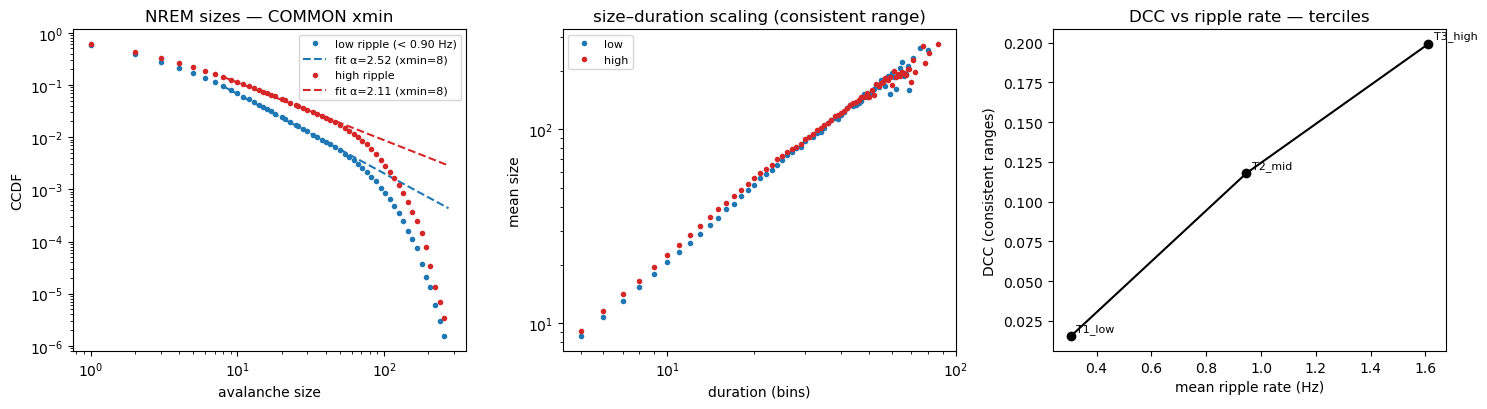

In [4]:
# --- figure: CCDFs with common-xmin fits + DCC by group ----------------------
S, D, rr, med = raw["S"], raw["D"], raw["rr"], raw["med"]
xmin_s = raw["xmin_s"]
lo, hi = S[rr <= med], S[rr > med]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
grid = np.unique(np.round(np.logspace(0, np.log10(S.max()), 80)))
for x, lab, c in ((lo, f"low ripple (< {med:.2f} Hz)", "tab:blue"),
                  (hi, f"high ripple", "tab:red")):
    ax.loglog(grid, ccdf_at(x[x > 0].astype(float), grid), "o", ms=3, label=lab, color=c)
    xs = x[(x >= xmin_s)].astype(float)
    a, _ = fit_powerlaw(xs, xmin_s, int(S.max()))
    th = np.logspace(np.log10(xmin_s), np.log10(S.max()), 50)
    anchor = ccdf_at(x[x > 0].astype(float), np.array([xmin_s]))[0]
    ax.loglog(th, anchor * (th / xmin_s) ** (-(a - 1)), "--", color=c,
              label=f"fit α={a:.2f} (xmin={xmin_s})")
ax.set_xlabel("avalanche size"); ax.set_ylabel("CCDF")
ax.set_title("NREM sizes — COMMON xmin"); ax.legend(fontsize=8)

ax = axes[1]
for x, lab, c in ((lo, "low", "tab:blue"), (hi, "high", "tab:red")):
    dd = D[rr <= med] if lab == "low" else D[rr > med]
    ud = np.unique(dd[dd >= raw["xmin_d"]])
    ms_ = np.array([x[dd == t].mean() for t in ud])
    ok = ms_ > 0
    ax.loglog(ud[ok], ms_[ok], "o", ms=3, color=c, label=lab)
ax.set_xlabel("duration (bins)"); ax.set_ylabel("mean size")
ax.set_title("size–duration scaling (consistent range)"); ax.legend(fontsize=8)

ax = axes[2]
sub = df[df.group.isin(["T1_low", "T2_mid", "T3_high"])]
ax.plot(sub.ripple_rate_mean, sub.DCC, "o-", color="k")
for _, r in sub.iterrows():
    ax.annotate(r.group, (r.ripple_rate_mean, r.DCC), fontsize=8,
                textcoords="offset points", xytext=(4, 4))
ax.set_xlabel("mean ripple rate (Hz)"); ax.set_ylabel("DCC (consistent ranges)")
ax.set_title("DCC vs ripple rate — terciles")

plt.tight_layout()
for ext in ("png", "svg"):
    p = safe_path(os.path.join(OUT_FIG_DIR, f"ripple_criticality_PPP20_day4.{ext}"))
    fig.savefig(p, dpi=200, bbox_inches="tight")
print("figures ->", OUT_FIG_DIR)

## Batch: all 18 Figure-1 sessions

Set `RUN_ALL = True` to run every session (≈ 3–6 min each; the xmin search dominates).
Accumulates one CSV (new file, `ripple_criticality_all_sessions.csv`) and runs the
paired low-vs-high statistics across sessions. Set `ABLATE = True` to repeat the whole
batch with ripple windows (±50 ms) excised — the control for the ripple events as the
second mixture component.

In [5]:
RUN_ALL = True
ABLATE  = False

if RUN_ALL:
    from run_fig1_metrics import FIG1_SESSIONS, session_id
    all_rows = []
    for bp in FIG1_SESSIONS:
        a, d = session_id(bp)
        sess = f"{a}_{d}"
        print(f"=== {sess} ===", flush=True)
        try:
            di, _ = run_session(bp, sess, ablate_ripples=ABLATE)
            all_rows.append(di)
        except Exception as e:
            print("  [FAIL]", sess, type(e).__name__, e)
    A = pd.concat(all_rows, ignore_index=True)
    tag = "_noripple" if ABLATE else ""
    p = safe_path(os.path.join(OUT_CSV_DIR, f"ripple_criticality_all_sessions{tag}.csv"))
    A.to_csv(p, index=False)
    print("wrote", p)

    from scipy.stats import wilcoxon
    piv = A[A.group.isin(["LOW", "HIGH"])].pivot_table(
        index="session", columns="group", values=["tau", "alpha", "DCC"])
    for metric in ("tau", "alpha", "DCC"):
        t = piv[metric].dropna()
        if len(t) >= 6:
            w, pv = wilcoxon(t.LOW, t.HIGH)
            print(f"{metric:>6s}: low={t.LOW.median():.3f} high={t.HIGH.median():.3f} "
                  f"n={len(t)} wilcoxon p={pv:.4f}")

=== PPP4_day11 ===


  ALL      rr=1.161 Hz  n= 563148  tau=2.175  alpha=2.424  beta_fit=1.216  DCC=0.004


  LOW      rr=0.856 Hz  n= 282745  tau=2.240  alpha=2.505  beta_fit=1.239  DCC=0.024


  HIGH     rr=1.468 Hz  n= 280403  tau=2.124  alpha=2.358  beta_fit=1.221  DCC=0.014


  T1_low   rr=0.793 Hz  n= 224566  tau=2.264  alpha=2.531  beta_fit=1.260  DCC=0.049
  T2_mid   rr=1.195 Hz  n= 166931  tau=2.144  alpha=2.397  beta_fit=1.211  DCC=0.011


  T3_high  rr=1.608 Hz  n= 171651  tau=2.120  alpha=2.342  beta_fit=1.235  DCC=0.036
=== PPP7_day7 ===


... (67 outputs left out)

  LOW      rr=0.833 Hz  n= 439589  tau=2.228  alpha=2.571  beta_fit=1.193  DCC=0.087


  HIGH     rr=1.631 Hz  n= 414341  tau=1.993  alpha=2.279  beta_fit=1.157  DCC=0.130
  T1_low   rr=0.702 Hz  n= 312043  tau=2.310  alpha=2.670  beta_fit=1.208  DCC=0.067


  T2_mid   rr=1.253 Hz  n= 262137  tau=2.069  alpha=2.366  beta_fit=1.184  DCC=0.093


  T3_high  rr=1.766 Hz  n= 279750  tau=1.970  alpha=2.255  beta_fit=1.156  DCC=0.137
wrote D:\Documents\GitHub\Sleep_criticaltiy\data\revision\log\ripple_criticality_all_sessions.csv
   tau: low=2.369 high=2.101 n=16 wilcoxon p=0.0001
 alpha: low=2.753 high=2.433 n=16 wilcoxon p=0.0001
   DCC: low=0.074 high=0.118 n=16 wilcoxon p=0.0155
